# Real-Time UPI Fraud Detection using XGBoost and SMOTE
**Dataset:** PaySim (simulated mobile-money transactions, similar to UPI transfers)

**Base paper:** Wenmeng Li, *Credit Card Fraud Detection: A System Based on Imbalanced Learning and Ensemble Models* (SMOTE + XGBoost)

**Base repo:** github.com/Jabezng2/Credit-Card-Fraud-Detection

**What I changed:** used PaySim instead of the credit card dataset, and added two balance-error features.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score, roc_auc_score)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

## 2. Load data

In [2]:
# Download PaySim from Kaggle (public dataset, no login needed)
import kagglehub, glob
path = kagglehub.dataset_download("ealaxi/paysim1")
csv_file = glob.glob(path + "/*.csv")[0]

df_full = pd.read_csv(csv_file)
print("Full dataset:", df_full.shape)

# 6 million rows is too big for free Colab, so take a 10% random sample
df = df_full.sample(frac=0.10, random_state=42)
del df_full
print("Sample:", df.shape)

Using Colab cache for faster access to the 'paysim1' dataset.
Full dataset: (6362620, 11)
Sample: (636262, 11)


In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
3737323,278,CASH_IN,330218.42,C632336343,20866.00,351084.42,C834976624,452419.57,122201.15,0,0
264914,15,PAYMENT,11647.08,C1264712553,30370.00,18722.92,M215391829,0.00,0.00,0,0
85647,10,CASH_IN,152264.21,C1746846248,106589.00,258853.21,C1607284477,201303.01,49038.80,0,0
5899326,403,TRANSFER,1551760.63,C333676753,0.00,0.00,C1564353608,3198359.45,4750120.08,0,0
2544263,206,CASH_IN,78172.30,C813403091,2921331.58,2999503.88,C1091768874,415821.90,337649.60,0,0


## 3. Explore the data
Fraud is very rare. This is the main problem the project solves.

In [4]:
print(df["isFraud"].value_counts())
print("Fraud %:", round(df["isFraud"].mean() * 100, 3))

isFraud
0    635445
1       817
Name: count, dtype: int64
Fraud %: 0.128


type
CASH_IN       0
CASH_OUT    402
DEBIT         0
PAYMENT       0
TRANSFER    415
Name: isFraud, dtype: int64


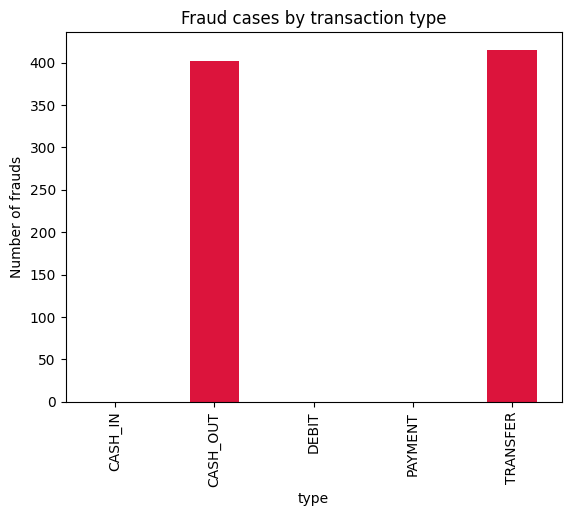

In [5]:
# Which transaction types have fraud?
print(df.groupby("type")["isFraud"].sum())

df.groupby("type")["isFraud"].sum().plot(kind="bar", color="crimson")
plt.title("Fraud cases by transaction type")
plt.ylabel("Number of frauds")
plt.show()

Fraud only happens in **TRANSFER** and **CASH_OUT**, so we keep only those two types.

## 4. Prepare features

In [6]:
df = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()

# Encode type as a number
df["type"] = df["type"].map({"TRANSFER": 0, "CASH_OUT": 1})

# New features: money that "goes missing" in the balances
df["errorBalanceOrig"] = df["newbalanceOrig"] + df["amount"] - df["oldbalanceOrg"]
df["errorBalanceDest"] = df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]

# Drop ID columns and the old rule-based flag
X = df.drop(columns=["isFraud", "nameOrig", "nameDest", "isFlaggedFraud"])
y = df["isFraud"]
print(X.columns.tolist())
print(X.shape)

['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'errorBalanceOrig', 'errorBalanceDest']
(277133, 9)


## 5. Train-test split (80/20)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train frauds:", y_train.sum(), "| Test frauds:", y_test.sum())

Train frauds: 654 | Test frauds: 163


## 6. Balance training data with SMOTE
SMOTE creates synthetic fraud examples so the model sees enough of them. Applied to **training data only**; the test set stays real.

In [8]:
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_sm.value_counts().to_dict())

Before SMOTE: {0: 221052, 1: 654}
After SMOTE:  {0: 221052, 1: 221052}


## 7. Train models

In [9]:
results = []

def evaluate(name, model, X_te):
    pred = model.predict(X_te)
    prob = model.predict_proba(X_te)[:, 1]
    results.append({
        "Model": name,
        "Precision": round(precision_score(y_test, pred), 3),
        "Recall": round(recall_score(y_test, pred), 3),
        "F1": round(f1_score(y_test, pred), 3),
        "ROC-AUC": round(roc_auc_score(y_test, prob), 3),
    })
    return pred

In [10]:
# Model 1: Logistic Regression (needs scaled data)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_sm)
X_test_sc = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_sc, y_train_sm)
evaluate("Logistic Regression + SMOTE", lr, X_test_sc)

array([0, 0, 0, ..., 0, 0, 1], shape=(55427,))

In [11]:
# Model 2: Random Forest
rf = RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=42)
rf.fit(X_train_sm, y_train_sm)
evaluate("Random Forest + SMOTE", rf, X_test)

array([0, 0, 0, ..., 0, 0, 0], shape=(55427,))

In [12]:
# Model 3: XGBoost WITHOUT SMOTE (to show SMOTE helps)
xgb_plain = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                          eval_metric="logloss", random_state=42)
xgb_plain.fit(X_train, y_train)
evaluate("XGBoost (no SMOTE)", xgb_plain, X_test)

array([0, 0, 0, ..., 0, 0, 0], shape=(55427,))

In [13]:
# Model 4: XGBoost + SMOTE (our final model)
xgb = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                    eval_metric="logloss", random_state=42)
xgb.fit(X_train_sm, y_train_sm)
xgb_pred = evaluate("XGBoost + SMOTE", xgb, X_test)

## 8. Compare results
We care most about **Recall** (how many frauds we catch) and **F1**. Accuracy is useless here: predicting "no fraud" every time gives 99.9% accuracy.

In [14]:
results_df = pd.DataFrame(results)
results_df

,Model,Precision,Recall,F1,ROC-AUC
0,Logistic Regression + SMOTE,0.057,0.933,0.107,0.987
1,Random Forest + SMOTE,1.000,1.000,1.000,1.000
2,XGBoost (no SMOTE),0.982,1.000,0.991,1.000
3,XGBoost + SMOTE,0.988,1.000,0.994,1.000


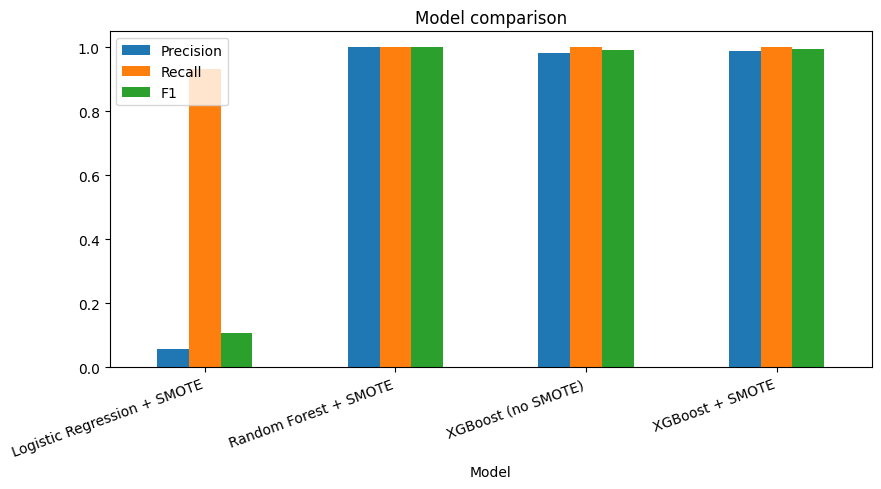

In [15]:
results_df.set_index("Model")[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(9, 5))
plt.title("Model comparison")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [19]:
# Extra test: XGBoost + SMOTE WITHOUT my balance-error features
cols = [c for c in X.columns if c not in ["errorBalanceOrig", "errorBalanceDest"]]
Xtr2, ytr2 = SMOTE(random_state=42).fit_resample(X_train[cols], y_train)
xgb2 = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                     eval_metric="logloss", random_state=42)
xgb2.fit(Xtr2, ytr2)
evaluate("XGBoost + SMOTE (no new features)", xgb2, X_test[cols])
pd.DataFrame(results)

,Model,Precision,Recall,F1,ROC-AUC
0,Logistic Regression + SMOTE,0.057,0.933,0.107,0.987
1,Random Forest + SMOTE,1.000,1.000,1.000,1.000
2,XGBoost (no SMOTE),0.982,1.000,0.991,1.000
3,XGBoost + SMOTE,0.988,1.000,0.994,1.000
4,XGBoost + SMOTE (no new features),0.422,0.975,0.589,0.999


## 9. Final model: XGBoost + SMOTE

              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     55264
       Fraud       0.99      1.00      0.99       163

    accuracy                           1.00     55427
   macro avg       0.99      1.00      1.00     55427
weighted avg       1.00      1.00      1.00     55427



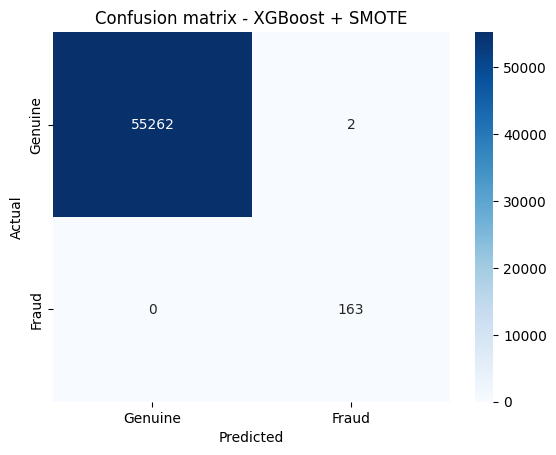

In [16]:
print(classification_report(y_test, xgb_pred, target_names=["Genuine", "Fraud"]))

cm = confusion_matrix(y_test, xgb_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Genuine", "Fraud"], yticklabels=["Genuine", "Fraud"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix - XGBoost + SMOTE")
plt.show()

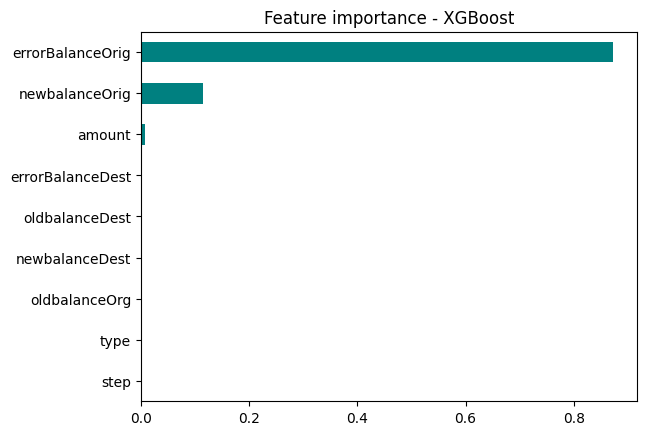

In [17]:
# Which features matter most?
imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", color="teal")
plt.title("Feature importance - XGBoost")
plt.show()

## 10. Try it: score one transaction

In [18]:
sample = X_test.iloc[[0]]
prob = xgb.predict_proba(sample)[0, 1]
print(sample.T)
print(f"\nFraud probability: {prob:.2%}")
print("BLOCK" if prob > 0.5 else "ALLOW")

                     3535489
step                  259.00
type                    1.00
amount             114899.78
oldbalanceOrg           0.00
newbalanceOrig          0.00
oldbalanceDest     983242.51
newbalanceDest    1098142.29
errorBalanceOrig   114899.78
errorBalanceDest        0.00

Fraud probability: 0.00%
ALLOW


## Conclusion
- Fraud is under 1% of transactions, so plain accuracy is misleading.
- SMOTE balanced the training data.
- XGBoost + SMOTE gave the best fraud detection among the models tested.
- Balance-error features were the strongest signals.

**Limitation:** PaySim is simulated data, not real UPI data. Real deployment would need bank transaction data.